# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns




### Cargar Dataset

In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv("/datasets/novaretail_comportamiento_clientes_2024.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [3]:
# mostrar las primeras 5 filas
df.head(5)

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
-edad
-nivel_ingreso
-visitas_mes
-compras_mes
-gasto_publicidad_dirigida
-satisfaccion
-ingreso_anual

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna edad está almacenada como float64, pero representa años completos, por lo que conviene convertirla a entero (int64). Las demás columnas numéricas tienen un tipo coherente con lo que miden: visitas_mes y compras_mes son conteos (enteros), y nivel_ingreso, gasto_publicidad_dirigida, satisfaccion e ingreso_anual son valores continuos (decimales).


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [4]:
# Corregir el tipo de dato
print("¿Hay edades con decimales?:", (df['edad'] % 1 != 0).any()) #Se verificó que ningún valor de edad tiene decimales, por lo que la conversión a int64 no altera la información.
df['edad'] = df['edad'].round().astype('int64')

¿Hay edades con decimales?: False


In [5]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [7]:
# Estadísticas descriptivas de variables numéricas
num_cols = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes',
            'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']
display(df[num_cols].describe().T)

# Detalles útiles para el diagnóstico
print("\n% de clientes con ingreso_anual = 0:", round((df['ingreso_anual'] == 0).mean() * 100, 2))
print("% de clientes con compras_mes = 0:    ", round((df['compras_mes'] == 0).mean() * 100, 2))
print("% de clientes con gasto_publicidad = 0:", round((df['gasto_publicidad_dirigida'] == 0).mean() * 100, 2))
print("\nAsimetría (skew):")
print(df[num_cols].skew().round(2))

,count,mean,std,min,25%,50%,75%,max
edad,15000.0,38.262400,11.492378,18.0,30.0000,38.000,46.0000,75.00
nivel_ingreso,15000.0,30019.704782,9833.166305,8000.0,23127.0975,30023.745,36768.4400,74790.84
visitas_mes,15000.0,10.029000,3.158189,1.0,8.0000,10.000,12.0000,25.00
compras_mes,15000.0,1.206467,1.105284,0.0,0.0000,1.000,2.0000,8.00
gasto_publicidad_dirigida,15000.0,20.149301,10.880724,0.0,12.3100,19.730,27.2925,75.51
satisfaccion,15000.0,3.603693,0.685300,1.0,3.1000,3.600,4.1000,5.00
ingreso_anual,15000.0,36.594180,34.484888,0.0,0.0000,30.705,58.2200,244.69



% de clientes con ingreso_anual = 0: 30.45
% de clientes con compras_mes = 0:     30.45
% de clientes con gasto_publicidad = 0: 3.0

Asimetría (skew):
edad                         0.23
nivel_ingreso                0.09
visitas_mes                  0.31
compras_mes                  0.90
gasto_publicidad_dirigida    0.34
satisfaccion                -0.15
ingreso_anual                1.04
dtype: float64




**Diagnóstico inicial de variables numéricas**


-edad: va de 18 a 75 años, con media de 38.3 y mediana de 38. Casi no hay asimetría (0.23), y el mínimo de 18 es coherente con una plataforma de clientes adultos.

-nivel_ingreso: va de 8,000 a 74,790.84, con media (30,019.7) y mediana (30,023.7) casi idénticas y asimetría de 0.09. Es la variable más simétrica del conjunto. Es el ingreso estimado del cliente, no el ingreso que genera para NovaRetail+, y no debe confundirse con ingreso_anual.

-visitas_mes: va de 1 a 25, con media de 10.03 y mediana de 10. Todos los clientes tienen al menos una visita, y la distribución es casi simétrica (asimetría 0.31), con una cola moderada hacia valores altos.

-compras_mes: va de 0 a 8, con media de 1.21 y mediana de 1. El 30.45% de los clientes tiene 0 compras en el mes, y la asimetría de 0.90 indica una --cola hacia la derecha: pocos clientes compran mucho. Es una variable de conteo con muchos ceros.

-gasto_publicidad_dirigida: va de 0 a 75.51, con media de 20.15 y mediana de 19.73. Solo el 3% de los clientes tiene gasto de 0, y la asimetría de 0.34 es leve.

-satisfaccion: va de 1 a 5 (dentro de la escala esperada), con media de 3.60 y mediana de 3.6. Tiene una ligera asimetría negativa (-0.15) y la mayoría de las calificaciones se concentra entre 3.1 y 4.1 (rango intercuartílico).

-ingreso_anual: va de 0 a 244.69, con media de 36.59 y mediana de 30.71. Es la variable con mayor asimetría (1.04) y su desviación estándar (34.48) es casi igual a la media, lo que indica mucha dispersión. El 30.45% de los clientes tiene ingreso de 0 y el máximo está muy por encima del percentil 75 (58.22).

***Observaciones relevantes para el análisis:***
Los clientes con compras_mes = 0 (4,567; 30.45%) son exactamente los mismos que tienen ingreso_anual = 0. Es una coincidencia observada en los datos: no hay clientes con compras e ingreso 0, ni con ingreso sin compras. Se espera por tanto una asociación alta entre ambas variables. Esto describe cómo se presentan juntas en el conjunto de datos; no permite afirmar que una determine a la otra.


In [8]:
print(pd.crosstab(df['compras_mes'] == 0, df['ingreso_anual'] == 0,
                  rownames=['compras_mes = 0'], colnames=['ingreso_anual = 0']))

ingreso_anual = 0  False  True 
compras_mes = 0                
False              10433      0
True                   0   4567


#### Explorar variables binarias

In [9]:
# Verificar que cada columna tenga únicamente dos valores posibles
bin_cols = ['miembro_premium', 'abandono']
for col in bin_cols:
    print(f"--- {col} ---")
    print("Valores únicos:", sorted(df[col].unique()))
    print(df[col].value_counts().to_frame('conteo').assign(
        porcentaje=lambda x: (x['conteo'] / len(df) * 100).round(2)))
    print()


--- miembro_premium ---
Valores únicos: [0, 1]
   conteo  porcentaje
0   12911       86.07
1    2089       13.93

--- abandono ---
Valores únicos: [0, 1]
   conteo  porcentaje
0   12739       84.93
1    2261       15.07





***Diagnóstico inicial de variables binarias***

miembro_premium: solo toma los valores 0 y 1, como se esperaba. 2,089 clientes (13.93%) son miembros premium y 12,911 (86.07%) no lo son. El grupo premium es una minoría, pero con 2,089 clientes tiene tamaño suficiente para compararlo con el resto.
abandono: solo toma los valores 0 y 1. 2,261 clientes (15.07%) abandonaron la plataforma y 12,739 (84.93%) no. Igual que en la variable anterior, el grupo minoritario es lo bastante grande para comparar.

***Observaciones relevantes para el análisis:***

Ambas variables están desbalanceadas (cerca de 86/14 y 85/15). Esto no es un error, pero hay que tenerlo presente al interpretar las correlaciones punto-biserial.
No hay valores distintos de 0 y 1 ni valores nulos, por lo que no requieren limpieza.
Los porcentajes describen cómo se distribuyen los clientes en el conjunto de datos. Todavía no dicen nada sobre cómo se relacionan estas variables con ingreso_anual; eso se evalúa más adelante con punto-biserial.


#### Explorar variables categóricas

In [11]:
# Verificar el número de valores únicos por variable categórica
cat_cols = ['id_cliente', 'tipo_dispositivo', 'region']
print(df[cat_cols].nunique())
print("\n¿id_cliente es único?:", df['id_cliente'].is_unique)

id_cliente          15000
tipo_dispositivo        3
region                  4
dtype: int64

¿id_cliente es único?: True


--- tipo_dispositivo ---
            conteo  porcentaje
móvil         9818       65.45
escritorio    3720       24.80
tablet        1462        9.75

--- region ---
       conteo  porcentaje
norte    4395       29.30
oeste    3810       25.40
sur      3726       24.84
este     3069       20.46

                  count   mean  median
tipo_dispositivo                      
escritorio         3720  36.42   30.44
móvil              9818  36.59   30.69
tablet             1462  37.07   31.34

        count   mean  median
region                      
este     3069  36.89   30.78
norte    4395  36.71   30.72
oeste    3810  35.72   30.36
sur      3726  37.10   30.94



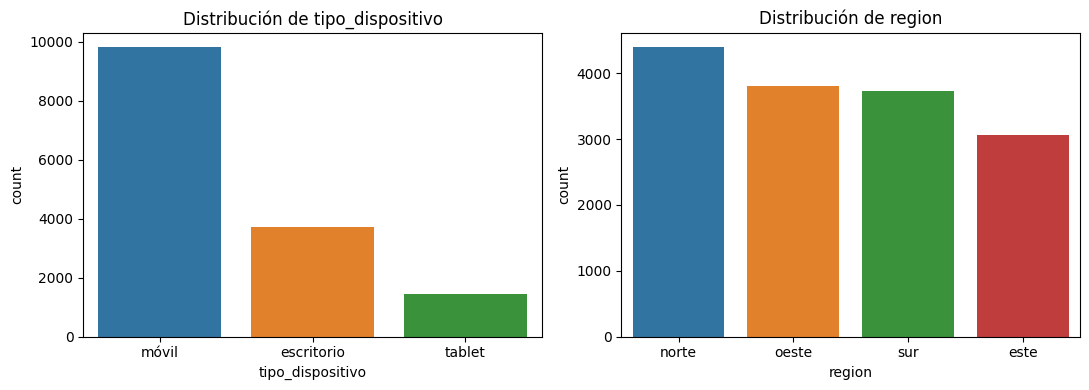

In [12]:
# Explorar variables categóricas y cómo se distribuyen
for col in ['tipo_dispositivo', 'region']:
    print(f"--- {col} ---")
    print(df[col].value_counts().to_frame('conteo').assign(
        porcentaje=lambda x: (x['conteo'] / len(df) * 100).round(2)))
    print()

# Vista rápida de cómo cambia el ingreso medio por categoría (descriptivo, no causal)
for col in ['tipo_dispositivo', 'region']:
    print(df.groupby(col)['ingreso_anual'].agg(['count', 'mean', 'median']).round(2))
    print()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ['tipo_dispositivo', 'region']):
    sns.countplot(data=df, x=col, ax=ax, order=df[col].value_counts().index)
    ax.set_title(f"Distribución de {col}")
plt.tight_layout()
plt.show()




***Diagnóstico inicial de variables categóricas***


-tipo_dispositivo: el dispositivo móvil es el más frecuente, con 9,818 clientes (65.45%). Le siguen escritorio con 3,720 (24.80%) y tablet con 1,462 (9.75%). Tablet es la categoría más pequeña, pero con más de 1,400 clientes tiene tamaño suficiente para compararla. El ingreso anual medio es muy parecido entre los tres grupos: 36.42 en escritorio, 36.59 en móvil y 37.07 en tablet. Las medianas también están cerca (30.44, 30.69 y 31.34). La diferencia entre el promedio más alto y el más bajo es de apenas 0.65.
-region: norte es la más numerosa, con 4,395 clientes (29.30%). Después vienen oeste con 3,810 (25.40%), sur con 3,726 (24.84%) y este con 3,069 (20.46%). Los promedios de ingreso anual también son cercanos: 36.89 en este, 36.71 en norte, 35.72 en oeste y 37.10 en sur. La región oeste tiene el promedio más bajo y sur el más alto, con una diferencia de 1.38. Las medianas van de 30.36 a 30.94.
id_cliente: es un identificador único (15,000 valores distintos) y no se usa en el análisis de asociaciones.

***Observaciones relevantes para el análisis:***

Ambas variables tienen un número bajo de categorías (3 y 4), sin errores de escritura ni categorías inesperadas.
La distribución no es uniforme, sobre todo en tipo_dispositivo (el móvil concentra casi dos tercios de los clientes), pero ninguna categoría es tan pequeña como para descartarla.
Las diferencias de ingreso medio entre categorías son pequeñas en comparación con la dispersión de ingreso_anual (desviación estándar de 34.48). Esto es solo una comparación descriptiva y no se aplicó ninguna prueba estadística, por lo que no podemos afirmar que tipo_dispositivo o region se asocien con el ingreso. Eso se evaluará más adelante con la V de Cramér y el resto de los análisis.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

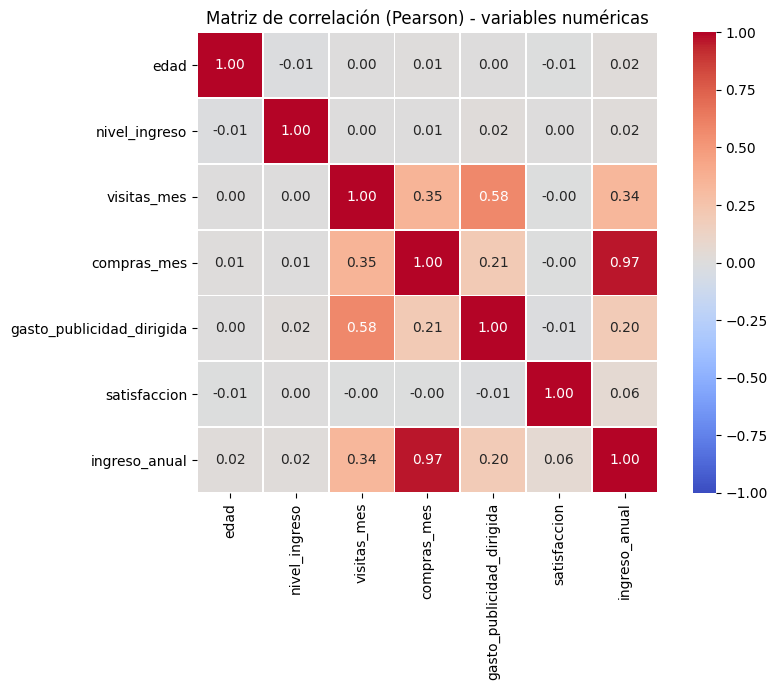

Correlación de cada variable con ingreso_anual (ordenada por magnitud):
compras_mes                  0.967
visitas_mes                  0.337
gasto_publicidad_dirigida    0.197
satisfaccion                 0.056
edad                         0.017
nivel_ingreso                0.017
Name: ingreso_anual, dtype: float64


In [13]:
# Visualizar la matriz de correlación para identificar relaciones
num_cols = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes',
            'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']
corr_matrix = df[num_cols].corr(method='pearson')

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Matriz de correlación (Pearson) - variables numéricas")
plt.tight_layout()
plt.show()

print("Correlación de cada variable con ingreso_anual (ordenada por magnitud):")
print(corr_matrix['ingreso_anual'].drop('ingreso_anual')
      .sort_values(key=abs, ascending=False).round(3))






**Observaciones generales (Heatmap)**

-La mayoría de las relaciones entre variables son cercanas a 0. edad, nivel_ingreso y satisfaccion casi no muestran correlación lineal con ninguna otra variable (valores entre -0.01 y 0.06).

-Las relaciones más visibles se concentran en el bloque de comportamiento: visitas_mes, compras_mes, gasto_publicidad_dirigida e ingreso_anual.

-La relación más alta entre variables explicativas es visitas_mes con gasto_publicidad_dirigida (0.58), de magnitud moderada. Le sigue visitas_mes con compras_mes (0.35) y compras_mes con gasto_publicidad_dirigida (0.21). Esto indica que estas variables se mueven parcialmente juntas, así que habrá que tener cuidado al interpretarlas por separado.

-Todas las correlaciones son positivas o cercanas a 0. No aparece ninguna correlación negativa relevante.

**Observaciones respecto a ingreso_anual**

-Presenta una correlación muy alta con compras_mes (0.967). Este valor es coherente con lo observado antes: los clientes con 0 compras son exactamente los que tienen ingreso 0. Es una asociación casi total que conviene leer con cautela, porque sus ceros coinciden exactamente y no sabemos cómo se registra cada variable.

-Con visitas_mes la correlación es moderada-baja (0.337) y con gasto_publicidad_dirigida es baja (0.197).

-Con satisfaccion (0.056), edad (0.017) y nivel_ingreso (0.017) las correlaciones son prácticamente nulas en términos lineales. En particular, el ingreso estimado del cliente (nivel_ingreso) no muestra asociación lineal con el ingreso que el cliente genera para NovaRetail+.

-Como visitas_mes y gasto_publicidad_dirigida están correlacionadas entre sí (0.58), parte de la asociación de cada una con ingreso_anual podría estar compartida con la otra y con compras_mes. Esto es una posibilidad a revisar, no una conclusión.

-Pearson solo mide relaciones lineales. Como ingreso_anual y compras_mes están sesgadas a la derecha y con muchos ceros, se complementará con Spearman en la Sección 4.

-Se trata de asociaciones y no de relaciones de causa y efecto.





### Scatterplot general

Con base en los resultados del análisis de correlación, evalúa si es necesario generar un *scatterplot* general.

- **Si decides incluirlo**:
  - Genera el gráfico.
  - Describe brevemente qué patrones o tendencias observas.

- **Si decides no incluirlo**:


***Decisión:*** sí se incluye el scatterplot general. Aunque el heatmap ya resume las correlaciones lineales, el gráfico permite confirmar si los valores cercanos a 0 esconden patrones no lineales y revisar la forma de las distribuciones (ceros, escalones, asimetría), algo que Pearson no muestra. Se usó una muestra de 2,000 clientes para que sea legible.

***Patrones observados:***

-Variables sin patrón visible: edad, nivel_ingreso y satisfaccion forman nubes dispersas frente a las demás variables, sin tendencia ni forma curva. Esto es coherente con sus correlaciones cercanas a 0. Tampoco se ve una relación no lineal que Pearson haya pasado por alto.

-compras_mes vs ingreso_anual: es la relación más clara del gráfico. Los puntos forman una secuencia ascendente casi lineal, agrupada en “escalones” porque compras_mes toma valores enteros. Con 0 compras el ingreso es 0, y el ingreso aumenta a medida que suben las compras.

-visitas_mes vs gasto_publicidad_dirigida: se aprecia una tendencia positiva moderada, con bastante dispersión. Es la relación más visible entre las variables explicativas, en línea con su correlación de 0.58.

-visitas_mes vs ingreso_anual y gasto_publicidad_dirigida vs ingreso_anual: hay una ligera inclinación positiva, pero con mucha dispersión.
Línea horizontal en ingreso_anual = 0: en todos los gráficos donde interviene ingreso_anual hay una franja de puntos en 0. Corresponde al 30.45% de clientes sin ingreso, que es el mismo grupo con 0 compras.

-Distribuciones (diagonal): ingreso_anual tiene un pico fuerte en 0, otro grupo alrededor de valores bajos-medios y una cola larga hacia la derecha (hasta unos 245). compras_mes se concentra entre 0 y 2, con pocos clientes en 5 o más. satisfaccion se concentra entre 3 y 4.5, con una acumulación en el máximo de 5.

-Outliers: se ven algunos clientes con ingreso_anual muy alto (más de 200) y compras_mes alto, pero siguen la misma línea ascendente de las compras, por lo que no parecen errores. También hay unos pocos valores altos de gasto_publicidad_dirigida (cerca de 70).

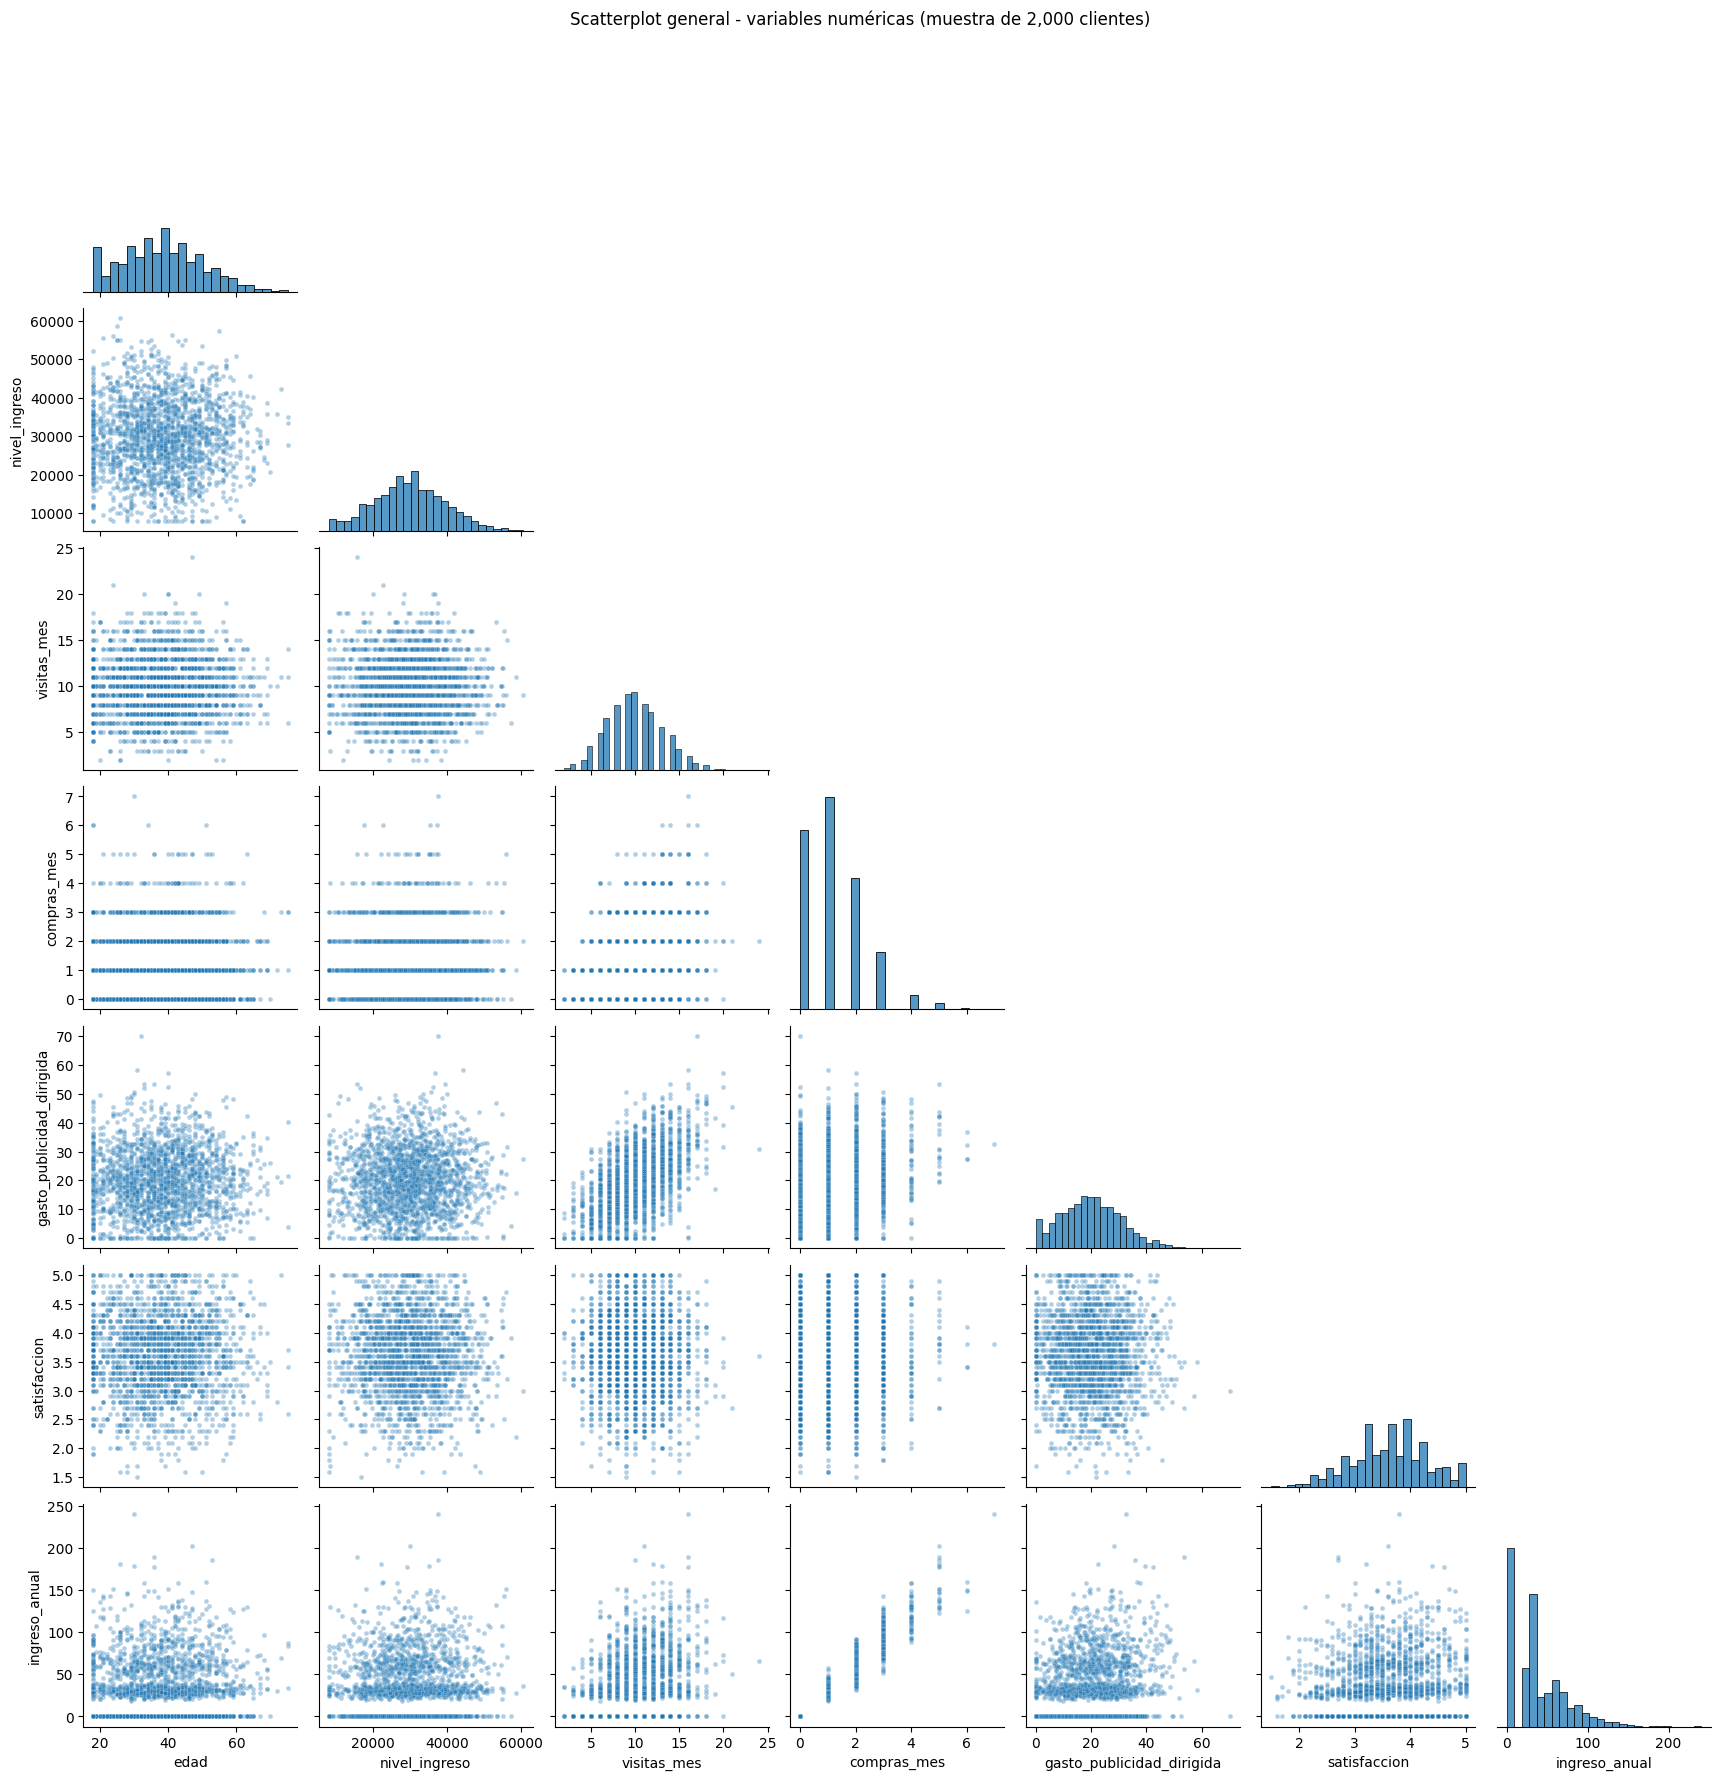

In [14]:
muestra = df[num_cols].sample(n=min(2000, len(df)), random_state=42)
sns.pairplot(muestra, corner=True, plot_kws={'alpha': 0.35, 's': 12}, diag_kind='hist')
plt.suptitle("Scatterplot general - variables numéricas (muestra de 2,000 clientes)", y=1.02)
plt.show()

### Scatterplot para pares clave

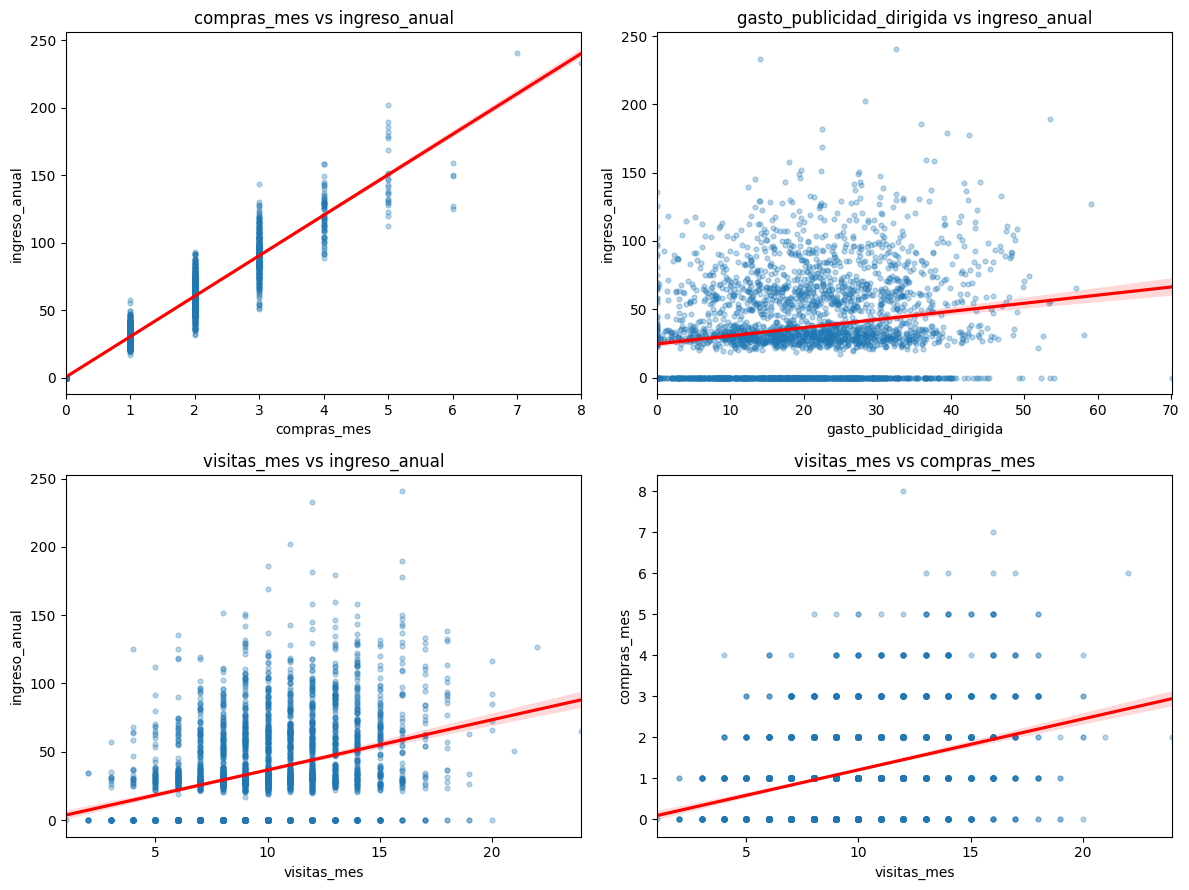

In [15]:
# Visualizar pares de variables con relaciones moderadas o fuertes
pares_clave = [
    ('compras_mes', 'ingreso_anual'),
    ('gasto_publicidad_dirigida', 'ingreso_anual'),
    ('visitas_mes', 'ingreso_anual'),
    ('visitas_mes', 'compras_mes'),
]

muestra = df.sample(n=min(3000, len(df)), random_state=42)
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (x, y) in zip(axes.ravel(), pares_clave):
    sns.regplot(data=muestra, x=x, y=y, ax=ax,
                scatter_kws={'alpha': 0.3, 's': 12}, line_kws={'color': 'red'})
    ax.set_title(f"{x} vs {y}")
plt.tight_layout()
plt.show()



**Observaciones iniciales (Scatterplot)**

***compras_mes vs ingreso_anual***

-Dirección: positiva y clara. A más compras mensuales, mayor ingreso anual; con 0 compras el ingreso es 0.

-Dispersión: baja. Los puntos se agrupan en columnas (una por cada valor entero de compras_mes) y siguen muy de cerca la línea de tendencia. La dispersión dentro de cada columna crece un poco al subir las compras (por ejemplo, con 1 compra el ingreso varía en un rango más estrecho que con 3 o 4).

-Outliers: son pocos y siguen la misma pendiente. Se ven algunos clientes con 5 a 7 compras e ingresos de 150 a 240, pero encajan en la tendencia, por lo que no parecen errores.

-Posible colinealidad: sí, es la relación más fuerte del análisis (r = 0.967). Sus ceros coinciden exactamente, así que conviene leer esta asociación con cautela y no tratarla como un hallazgo independiente..

***gasto_publicidad_dirigida vs ingreso_anual***

-Dirección: positiva pero débil. La línea de tendencia sube suavemente, de unos 25 a unos 65 a lo largo de todo el rango de gasto.

-Dispersión: alta. Para un mismo nivel de gasto hay clientes con ingreso 0 y otros por encima de 150. La franja de puntos en ingreso_anual = 0 se mantiene a lo largo de todo el rango de gasto.

-Outliers: hay clientes con ingreso muy alto (más de 200) con gasto bajo o medio, y algunos con gasto cercano a 70. No se ve un patrón que sugiera errores.

-Posible colinealidad: la relación con ingreso_anual es baja (0.197), pero gasto_publicidad_dirigida está relacionada con visitas_mes (0.58), por lo que parte de su asociación con el ingreso podría ser compartida con esa variable.

***visitas_mes vs ingreso_anual***

-Dirección: positiva, de magnitud baja a moderada (r = 0.337). La línea de tendencia sube de forma gradual.

-Dispersión: alta. Los puntos forman columnas verticales (porque visitas_mes es entera) y cada columna cubre desde 0 hasta más de 100 en ingreso. La franja en 0 aparece en todos los niveles de visitas.

-Outliers: se ven clientes con ingreso de 150 a 240 con 10 a 16 visitas. Por encima de 18 visitas hay pocos puntos, así que la tendencia ahí es menos confiable.

-Posible colinealidad: moderada con compras_mes (0.35) y con gasto_publicidad_dirigida (0.58).

***visitas_mes vs compras_mes***

-Dirección: positiva y moderada (r = 0.35). La línea de tendencia sube con claridad, pero con mucha dispersión.

-Dispersión: alta. Hay clientes con muchas visitas (hasta 20) y 0 compras, y clientes con pocas visitas que sí compran. La nube forma una cuadrícula por ser dos variables de conteo.

-Outliers: se ve un cliente con 8 compras y 12 visitas, y otros con 6 o 7 compras. Son valores extremos pero plausibles.

-Posible colinealidad: moderada-baja, sin llegar a un nivel preocupante. Las visitas y las compras se mueven juntas solo en parte.

-Nota general: como el 30.45% de los clientes tiene ingreso_anual = 0, la línea de tendencia en los gráficos con ingreso_anual queda influida por ese grupo, y esa franja se ve en todos ellos. Los gráficos muestran asociaciones, no relaciones de causa y efecto.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [16]:
# Calcular correlación entre variables relevantes (pearson)
pearson = (df[num_cols].corr(method='pearson')['ingreso_anual']
           .drop('ingreso_anual').rename('pearson'))
print(pearson.sort_values(key=abs, ascending=False).round(3))

compras_mes                  0.967
visitas_mes                  0.337
gasto_publicidad_dirigida    0.197
satisfaccion                 0.056
edad                         0.017
nivel_ingreso                0.017
Name: pearson, dtype: float64


In [17]:
# Calcular correlación entre variables relevantes (spearman)
spearman = (df[num_cols].corr(method='spearman')['ingreso_anual']
            .drop('ingreso_anual').rename('spearman'))

comparacion = pd.concat([pearson, spearman], axis=1)
comparacion['diferencia_abs'] = (comparacion['pearson'] - comparacion['spearman']).abs()
print(comparacion.sort_values('spearman', key=abs, ascending=False).round(3))

# Posible colinealidad entre predictores (|r| >= 0.60)
pred = df[num_cols].drop(columns='ingreso_anual').corr(method='pearson')
pares = (pred.where(np.triu(np.ones(pred.shape), k=1).astype(bool))
         .stack().rename('r').reset_index())
print("\nPares de predictores con |r| >= 0.60 (posible colinealidad):")
print(pares[pares['r'].abs() >= 0.60].round(3).to_string(index=False))

                           pearson  spearman  diferencia_abs
compras_mes                  0.967     0.967           0.000
visitas_mes                  0.337     0.321           0.016
gasto_publicidad_dirigida    0.197     0.185           0.012
satisfaccion                 0.056     0.061           0.005
nivel_ingreso                0.017     0.025           0.008
edad                         0.017     0.016           0.001

Pares de predictores con |r| >= 0.60 (posible colinealidad):
Empty DataFrame
Columns: [level_0, level_1, r]
Index: []



**Observaciones de correlación**

***compras_mes vs ingreso_anual***

-Correlación: positiva y muy alta, con Pearson = 0.967 y Spearman = 0.967 (diferencia de 0.000). Es la asociación más fuerte del conjunto de datos.

-Que ambos coeficientes coincidan indica que la relación es a la vez lineal y monótona, y que los ceros, la asimetría y los valores extremos no la distorsionan.

- Esta asociación debe leerse con cautela: sus ceros coinciden exactamente (4,567 clientes), por lo que no conviene tratarla como un hallazgo independiente.

***visitas_mes vs ingreso_anual***

-Correlación: positiva, baja a moderada (Pearson = 0.337, Spearman = 0.321). Es la segunda asociación más alta, pero muy por debajo de la de compras.

-La diferencia entre ambos métodos es pequeña (0.016), así que el patrón es estable. Con Pearson, la variable comparte aproximadamente el 11% de la variabilidad del ingreso (r² ≈ 0.11).

***gasto_publicidad_dirigida vs ingreso_anual***

-Correlación: positiva y baja (Pearson = 0.197, Spearman = 0.185). Existe una asociación, pero es modesta.

-Con los métodos coincidiendo, no se ve que los valores extremos estén afectando el resultado.

***satisfaccion, nivel_ingreso y edad vs ingreso_anual***

-Correlación: prácticamente nula en los tres casos (satisfaccion: 0.056 y 0.061; nivel_ingreso: 0.017 y 0.025; edad: 0.017 y 0.016).

-Spearman y Pearson coinciden, así que tampoco hay una relación monótona oculta que Pearson no detecte. El ingreso estimado del cliente y su edad no muestran asociación con el ingreso que genera para NovaRetail+.

***Comparación Pearson vs Spearman***

-La diferencia absoluta máxima entre ambos coeficientes es de 0.016. Los resultados son consistentes y no dependen de la forma de las distribuciones.

****Posible colinealidad entre variables explicativas****

- Ningún par de variables explicativas alcanza |r| ≥ 0.60 (la tabla sale vacía), por lo que no hay colinealidad fuerte.

- El par más cercano es `visitas_mes` con `gasto_publicidad_dirigida` (0.58, visto en el heatmap). Parte de su asociación con `ingreso_anual` puede ser compartida, así que conviene no leerlas como efectos separados.

Todas son asociaciones: no permiten afirmar que una variable provoque cambios en otra.

### Punto-biserial

In [18]:
# Calcular correlación entre variables relevantes
from scipy.stats import pointbiserialr

resultados = []
for b in ['miembro_premium', 'abandono']:
    for n in ['ingreso_anual', 'compras_mes', 'visitas_mes', 'satisfaccion']:
        r, p = pointbiserialr(df[b], df[n])
        resultados.append({'binaria': b, 'numerica': n, 'r_pb': round(r, 3), 'p_value': p})

pb = pd.DataFrame(resultados)
display(pb)

# Apoyo descriptivo: media de ingreso_anual por grupo
for b in ['miembro_premium', 'abandono']:
    print(df.groupby(b)['ingreso_anual'].agg(['count', 'mean', 'median']).round(2), "\n")

,binaria,numerica,r_pb,p_value
0,miembro_premium,ingreso_anual,0.093,3.094308e-30
1,miembro_premium,compras_mes,0.003,6.743982e-01
2,miembro_premium,visitas_mes,-0.013,1.211330e-01
3,miembro_premium,satisfaccion,0.026,1.621474e-03
4,abandono,ingreso_anual,-0.003,7.294692e-01
5,abandono,compras_mes,0.008,3.099365e-01
6,abandono,visitas_mes,-0.009,2.734362e-01
7,abandono,satisfaccion,-0.024,3.510977e-03


                 count   mean  median
miembro_premium                      
0                12911  35.30   29.95
1                 2089  44.58   37.70 

          count   mean  median
abandono                      
0         12739  36.64   30.69
1          2261  36.36   30.72 



✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico.   
Incluye qué ves: dirección (positiva o negativa), magnitud (alta, media, baja).

**Observaciones Punto-biserial**

***miembro_premium vs ingreso_anual***

-Relación: positiva y baja (r_pb = 0.093). Es la asociación más alta entre las variables binarias, pero de magnitud pequeña (comparte menos del 1% de la variabilidad, r² ≈ 0.009).

-Descriptivamente, los clientes premium tienen un ingreso anual medio de 44.58 frente a 35.30 de los no premium (una diferencia de 9.28, cerca de 26% más), y una mediana de 37.70 frente a 29.95.

-El p-valor es muy pequeño (3.09e-30), por lo que la diferencia no parece fruto del azar. Con 15,000 registros, hasta asociaciones débiles resultan significativas, así que lo relevante es la magnitud, que es modesta.

**miembro_premium vs compras_mes, visitas_mes y satisfaccion**

-compras_mes: relación nula (r_pb = 0.003, p = 0.67). Los clientes premium no muestran más compras mensuales que los demás. Este contraste con el ingreso merece revisarse más adelante.

-visitas_mes: relación nula (r_pb = -0.013, p = 0.12).

-satisfaccion: relación muy baja (r_pb = 0.026, p = 0.0016). Es estadísticamente significativa, pero de magnitud despreciable.

**abandono vs ingreso_anual**

-Relación: nula (r_pb = -0.003, p = 0.73). El ingreso medio es casi igual en ambos grupos (36.64 para quienes no abandonaron y 36.36 para quienes sí), y las medianas también (30.69 y 30.72).

-En estos datos, el ingreso anual no distingue a los clientes que abandonaron de los que no.

**abandono vs compras_mes, visitas_mes y satisfaccion**

-compras_mes: nula (r_pb = 0.008, p = 0.31).

-visitas_mes: nula (r_pb = -0.009, p = 0.27).

-satisfaccion: muy baja y negativa (r_pb = -0.024, p = 0.0035). Es significativa, pero con una magnitud demasiado pequeña para tener relevancia práctica.

Resumen: la única relación binaria-numérica con alguna relevancia es miembro_premium con ingreso_anual, y aun así es baja. abandono no muestra asociación relevante con ninguna de las variables evaluadas. Son asociaciones, no efectos: no podemos afirmar que ser premium aumente el ingreso ni que la satisfacción se relacione con abandonar.

### V de Cramér

In [20]:
# Función para calcular V de Cramér
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla, correction=False)[0]
    n = tabla.values.sum()
    r, k = tabla.shape
    # Corrección de sesgo (Bergsma)
    phi2 = max(0, chi2 / n - ((k - 1) * (r - 1)) / (n - 1))
    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)
    return np.sqrt(phi2 / min(k_corr - 1, r_corr - 1))

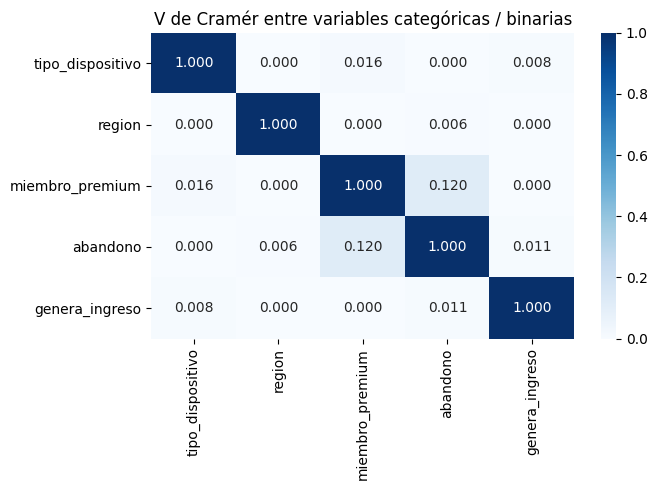

Asociación de cada variable con genera_ingreso:
abandono            0.011
tipo_dispositivo    0.008
region              0.000
miembro_premium     0.000
Name: genera_ingreso, dtype: float64


In [21]:
# Aplicar V de Cramér en variables relevantes
df_v = df.copy()
df_v['genera_ingreso'] = (df_v['ingreso_anual'] > 0).astype(int)

vars_cat = ['tipo_dispositivo', 'region', 'miembro_premium', 'abandono', 'genera_ingreso']
matriz_v = pd.DataFrame(index=vars_cat, columns=vars_cat, dtype=float)
for a in vars_cat:
    for b in vars_cat:
        matriz_v.loc[a, b] = 1.0 if a == b else cramers_v(df_v[a], df_v[b])

plt.figure(figsize=(7, 5))
sns.heatmap(matriz_v.astype(float), annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1)
plt.title("V de Cramér entre variables categóricas / binarias")
plt.tight_layout()
plt.show()

print("Asociación de cada variable con genera_ingreso:")
print(matriz_v['genera_ingreso'].drop('genera_ingreso').sort_values(ascending=False).round(3))


In [22]:
print(pd.crosstab(df['miembro_premium'], df['abandono'], normalize='index').round(3) * 100)

abandono            0     1
miembro_premium            
0                83.2  16.8
1                95.6   4.4


**Observaciones V de Cramér**
Para esta prueba se creó la variable auxiliar genera_ingreso (1 si ingreso_anual > 0, 0 si es 0), porque la V de Cramér compara variables categóricas. Como los ceros de ingreso coinciden con los de compras, esta variable también equivale a “el cliente compró en el mes”. La V de Cramér va de 0 a 1 y no indica dirección. Como referencia, valores menores a 0.10 se consideran asociación despreciable y entre 0.10 y 0.30, débil.

***miembro_premium vs abandono (V = 0.120):*** es la única asociación que supera 0.10, y es débil. Hay un vínculo estadístico entre ser miembro premium y haber abandonado la plataforma, pero la V no dice en qué sentido. Para conocer la dirección hay que mirar los porcentajes de abandono en cada grupo.

***Asociaciones con genera_ingreso:*** son despreciables en todos los casos: abandono (0.011), tipo_dispositivo (0.008), region (0.000) y miembro_premium (0.000). Ni el dispositivo, ni la región, ni ser premium, ni abandonar distinguen a los clientes que tienen ingreso de los que no.

***tipo_dispositivo y region:*** no muestran asociación relevante con ninguna otra variable (valores entre 0.000 y 0.016), ni entre sí (0.000). Los clientes se distribuyen de forma similar entre dispositivos y regiones en cuanto a premium, abandono e ingreso.

***miembro_premium vs genera_ingreso (V = 0.000):*** junto con la correlación punto-biserial anterior (0.093 con `ingreso_anual`), sugiere que la diferencia de ingreso de los clientes premium no está en si tienen ingreso, sino en cuánto ingreso registran. Es una observación descriptiva que habría que revisar con un análisis más detallado.
Estos valores describen asociaciones y no permiten afirmar que una variable provoque cambios en otra.



## Sección 5 - Interpretación de resultados para el negocio

Cada hallazgo  debe incluir:
1) Evidencia visual (si aplica)
2) Evidencia numérica  
3) Interpretación (no causal)  
4) No podemos afirmar
5) Implicación de negocio

---


### Hallazgo 1 — Las compras mensuales y el ingreso anual casi se mueven juntos

-**Evidencia visual:** en el heatmap, `compras_mes` e `ingreso_anual` tienen la celda más intensa fuera de la diagonal. En el scatterplot de pares clave, los puntos forman columnas ordenadas que siguen de cerca la línea de tendencia ascendente, y con 0 compras el ingreso es 0.

-**Evidencia numérica:** Pearson = 0.967 y Spearman = 0.967. Los 4,567 clientes (30.45%) con `compras_mes` = 0 son exactamente los mismos con `ingreso_anual` = 0; los otros 10,433 tienen ambos valores mayores que 0.

-**Interpretación**  
Los clientes que registran más compras en el mes tienden a registrar un ingreso anual mayor. Es la asociación más fuerte del análisis y es consistente tanto en lo lineal como en lo monótono. Como sus ceros coinciden exactamente, conviene leerla con cautela y no como un hallazgo independiente; no sabemos cómo se registra cada variable.

-**No podemos afirmar**  
Que aumentar las compras de un cliente aumente su ingreso anual, ni que una variable determine a la otra. Tampoco que la relación se mantenga si se midieran en periodos distintos (`compras_mes` es mensual e `ingreso_anual` es anual).

-**Implicación de negocio**  
El grupo de clientes sin compras (30.45%) es también el grupo sin ingreso, por lo que es un segmento prioritario para analizar y diseñar acciones de activación. Conviene evaluar esas acciones con pruebas controladas antes de asumir su efecto.



### Hallazgo 2 — Visitas y gasto en publicidad dirigida muestran asociaciones menores con el ingreso, y se relacionan entre sí

-**Evidencia visual:** en los scatterplots, `visitas_mes` y `gasto_publicidad_dirigida` frente a `ingreso_anual` muestran una inclinación positiva suave con mucha dispersión y la franja de ceros en todos los niveles. Entre `visitas_mes` y `gasto_publicidad_dirigida` se ve una tendencia positiva más marcada.

-**Evidencia numérica:** `visitas_mes` vs `ingreso_anual`: Pearson = 0.337 y Spearman = 0.321. `gasto_publicidad_dirigida` vs `ingreso_anual`: Pearson = 0.197 y Spearman = 0.185. Entre sí: `visitas_mes` y `gasto_publicidad_dirigida` = 0.58; `visitas_mes` y `compras_mes` = 0.35.

-**Interpretación**  
Los clientes con más visitas y con mayor gasto publicitario asignado tienden a tener un ingreso algo mayor, aunque la asociación es baja a moderada y deja mucha variabilidad sin acompañar. Como visitas y gasto también están relacionadas entre sí, parte de lo que cada una muestra frente al ingreso puede ser compartido.

-**No podemos afirmar**  
Que más visitas o más gasto publicitario generen más ingreso, ni que la publicidad sea eficaz. El gasto es una asignación por usuario y no sabemos con qué criterio se asignó; podría haberse dirigido a usuarios ya más activos.

-**Implicación de negocio**  
Estos datos no bastan para justificar aumentar el gasto en publicidad dirigida. Antes de decidirlo, conviene medir su efecto con una prueba controlada (por ejemplo, un test A/B) y comparar clientes con nivel de actividad similar.


# Hallazgo 3 — Ser miembro premium se asocia con mayor ingreso y menor abandono, pero con magnitud modesta

**Evidencia visual:** en la matriz de V de Cramér, `miembro_premium` con `abandono` es la única celda fuera de la diagonal que se distingue del resto (0.120). 

**Evidencia numérica:** `miembro_premium` vs `ingreso_anual`: r_pb = 0.093 (p = 3.09e-30). Ingreso medio de 44.58 en premium frente a 35.30 en no premium (mediana de 37.70 frente a 29.95). Abandono: 4.4% en premium frente a 16.8% en no premium (V de Cramér = 0.120). Premium vs `compras_mes`: r_pb = 0.003. Premium vs `genera_ingreso`: V = 0.000.

**Interpretación**  
Los clientes premium tienden a presentar un ingreso anual algo mayor y una tasa de abandono menor que el resto. La asociación con el ingreso es pequeña (comparte menos del 1% de la variabilidad), aunque estadísticamente consistente por el tamaño de la muestra. Llama la atención que premium no se asocie con más compras mensuales ni con generar o no ingreso: la diferencia parece estar en cuánto ingreso se registra, no en si se compra.

**No podemos afirmar**  
Que la membresía premium aumente el ingreso o reduzca el abandono. Los clientes que se hacen premium pueden ser distintos de los demás desde el inicio (por ejemplo, más comprometidos con la plataforma). Tampoco sabemos por qué el ingreso es mayor sin más compras.

**Implicación de negocio**  
Premium es un segmento relevante para el análisis de retención e ingreso. Conviene investigar qué compone la diferencia de ingreso (por ejemplo, el valor por compra) y evaluar con una prueba controlada cualquier iniciativa para incentivar la membresía.

### Hallazgo 4 — Edad, nivel de ingreso, satisfacción, dispositivo y región no muestran asociación relevante con el ingreso anual

**Evidencia visual:** en el heatmap, las celdas de `edad`, `nivel_ingreso` y `satisfaccion` frente a `ingreso_anual` son casi neutras, y en el pairplot forman nubes sin patrón. En la matriz de V de Cramér, `tipo_dispositivo` y `region` están cerca de 0 con todas las variables.

**Evidencia numérica:** frente a `ingreso_anual`: `edad` = 0.017, `nivel_ingreso` = 0.017 y `satisfaccion` = 0.056 (Pearson); Spearman similar. V de Cramér con `genera_ingreso`: `tipo_dispositivo` = 0.008 y `region` = 0.000. Ingreso medio por dispositivo entre 36.42 y 37.07 y por región entre 35.72 y 37.10. `abandono` vs `ingreso_anual`: r_pb = -0.003.

**Interpretación**  
En estos datos, el perfil demográfico del cliente, su ingreso estimado, su satisfacción, el dispositivo, la región y el hecho de haber abandonado no ayudan a distinguir a los clientes de mayor ingreso. Las asociaciones relevantes se concentran en variables de comportamiento (compras, visitas, gasto asignado) y, en menor medida, en la membresía premium.

**No podemos afirmar**  
Que estas variables sean irrelevantes para el negocio: los coeficientes solo detectan relaciones lineales o monótonas y no evalúan combinaciones entre variables. Tampoco que el abandono no implique una pérdida de ingreso futuro, porque no hay información temporal.

**Implicación de negocio**  
Para segmentar por ingreso, conviene priorizar variables de comportamiento antes que variables demográficas o de dispositivo. Además, conviene revisar cómo se define `abandono`, ya que en estos datos no distingue a los clientes por ingreso.

## Sección 6 - Limitaciones y próximos pasos


### **Limitaciones**
- Correlación ≠ causalidad: todos los resultados son asociaciones y no permiten concluir efectos.
- `compras_mes` e `ingreso_anual` tienen los mismos ceros (4,567 clientes) y una correlación de 0.967, por lo que esa asociación es casi redundante y no es un hallazgo independiente.
- Los datos son de un solo corte, sin información temporal. Además, `compras_mes` y `visitas_mes` son mensuales mientras que `ingreso_anual` es anual.
- Pearson y Spearman miden relaciones lineales o monótonas entre pares de variables; no se evaluaron combinaciones de variables ni interacciones (por ejemplo, visitas y gasto juntos).
- `gasto_publicidad_dirigida` es una asignación por usuario y no sabemos con qué criterio se hizo, por lo que no puede leerse como un experimento.
- Con 15,000 registros, hasta asociaciones muy pequeñas resultan estadísticamente significativas; se priorizó la magnitud de los coeficientes sobre el p-valor.
- La variable `genera_ingreso` es auxiliar y se creó solo para la V de Cramér.

### **Próximos pasos** 

Probar segmentación adicional
- Repetir las correlaciones solo con los clientes que tienen compras (`compras_mes` > 0), para ver qué se asocia con el ingreso sin la influencia de los ceros.
- Comparar el ingreso por valor por compra entre clientes premium y no premium.

Análisis multivariado
- Ajustar un modelo de regresión múltiple para ver cómo se asocia cada variable con el ingreso al considerar las demás a la vez.
- Revisar la relación conjunta entre visitas y gasto publicitario.

Validación causal
- Diseñar una prueba controlada (A/B) para evaluar el efecto del gasto en publicidad dirigida y de incentivos a la membresía premium.
- Incorporar datos por periodo o cohorte para analizar la evolución del ingreso y del abandono en el tiempo.